In [1]:
from pathlib import Path
import os
import pyrootutils
root = pyrootutils.setup_root(search_from=Path(os.getcwd()), indicator=[".project-root"], pythonpath=True)

import pandas as pd
import numpy as np
import seaborn as sns

# Will be used as pertubators.
from numpy.random import normal, uniform

# Classification metrics, train_test split and diabetes dataset from skLearn
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# We will compare the robustness of the following 2 models
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from algorithms.robustness.assessment.classification import ClassificationRobustnessAssessment

Comparing accuracy and robustness of a RandomForestClassifier model and an SVM model over the iris dataset.

In [2]:
# Load data
X, y = load_iris(return_X_y=True)

# Train/test split of data
train_test_split_args = {'test_size':0.33, 'random_state':42}
X_train, X_test, y_train, y_test = train_test_split(X, y, **train_test_split_args)

# Fit a RandomForestClassifier model to dataset
model_RFC = RandomForestClassifier()
model_RFC.fit(X_train, y_train)

# Fit a SVM model
svc_args = {'kernel':'rbf', 'C':1.0, 'gamma':0.1}
model_SVC = SVC(**svc_args)
model_SVC.fit(X_train, y_train)

# Make a prediction on the test set
y_pred_RFC = model_RFC.predict(X_test)
y_pred_SVC = model_SVC.predict(X_test)

In [3]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [4]:
# As suggested by section Themis D2.1 section 2.3.4.2.2
# Robustness is computed with respect to:
# - An accuracy metric. Or a set of accuracy metrics.
# - Some pertubation of the dataset

In [5]:
# Let us consider the following metrics relevant to classification problems
# We rely on their SKLearn implementation 
considered_metrics = {
    accuracy_score:{},
    # NOTE: This may need to aggregated down to a scalar.
    # We use the 'micro' argument for now
    f1_score:{'average':'micro'}, 
    matthews_corrcoef:{}
}

# Let us consider the following arbitrary perturbations
# that will be applied to test feature vector
# We define normal noise generators that will be used to disturb the dataset
norm_args = {'loc':0.0, 'size':X_test.shape}
considered_perturbations = {
    'normal_0_01':{
        'func':normal,
        'args':{'scale':10.0, **norm_args}
    },
    'normal_0_001':{
        'func':normal,
        'args':{'scale':1.00, **norm_args}
    },
    'normal_0_0001':{
        'func':normal,
        'args':{'scale':0.10, **norm_args}
    },
    'normal_0_00001':{
        'func':normal,
        'args':{'scale':0.01, **norm_args}
    },
    'uniform_0_5':{
        'func':uniform,
        'args':{'high':0.5}
    },
    'uniform_1':{
        'func':uniform,
        'args':{'high':1}
    },
}

In [6]:
# Evaluate RandomForestClassifier model using the considered metrics
clean_metrics_RFC = {
    func.__name__:func(y_test, y_pred_RFC, **args) for func, args in considered_metrics.items()
}
clean_metrics_RFC

{'accuracy_score': 0.98,
 'f1_score': 0.98,
 'matthews_corrcoef': 0.9704463208685162}

In [7]:
# Evaluate Support Vector Machine model using the considered metrics
clean_metrics_SVC = {
    func.__name__:func(y_test, y_pred_SVC, **args) for func, args in considered_metrics.items()
}
clean_metrics_SVC

{'accuracy_score': 1.0, 'f1_score': 1.0, 'matthews_corrcoef': 1.0}

In [8]:
all_pertub_metrics_RFC = {}
all_pertub_metrics_SVC = {}

for perturb_name, pertub_args in considered_perturbations.items():
    # Pertub the input data
    X_test_pertubed = X_test + pertub_args['func'](**pertub_args['args'])

    # Predict using the model trained on original dataset but on data
    # that was pertubed 
    y_pred_RFC = model_RFC.predict(X_test_pertubed)

    perturb_metrics = {
        func.__name__:func(y_test, y_pred_RFC, **args) for func, args in considered_metrics.items()
    }

    all_pertub_metrics_RFC[perturb_name] = perturb_metrics

    y_pred_SVC = model_SVC.predict(X_test_pertubed)

    perturb_metrics = {
        func.__name__:func(y_test, y_pred_SVC, **args) for func, args in considered_metrics.items()
    }

    all_pertub_metrics_SVC[perturb_name] = perturb_metrics
    

In [9]:
perturb_metrics_RFC = pd.DataFrame(all_pertub_metrics_RFC).transpose()
perturb_metrics_RFC

,accuracy_score,f1_score,matthews_corrcoef
normal_0_01,0.40,0.40,0.087087
normal_0_001,0.70,0.70,0.559807
normal_0_0001,0.98,0.98,0.970446
normal_0_00001,0.98,0.98,0.970446
uniform_0_5,0.98,0.98,0.970446
uniform_1,0.60,0.60,0.448501


In [10]:
perturb_metrics_SVC = pd.DataFrame(all_pertub_metrics_SVC).transpose()
perturb_metrics_SVC

,accuracy_score,f1_score,matthews_corrcoef
normal_0_01,0.32,0.32,0.000000
normal_0_001,0.74,0.74,0.609535
normal_0_0001,1.00,1.00,1.000000
normal_0_00001,1.00,1.00,1.000000
uniform_0_5,1.00,1.00,1.000000
uniform_1,0.74,0.74,0.679303


In [11]:
#Initialize robustness analayser for classification model given the provided perturbation methods:
robustness_analyzer_SVC = ClassificationRobustnessAssessment(considered_perturbations)
robustness_analyzer_RFC = ClassificationRobustnessAssessment(considered_perturbations)

In [12]:
# Themis D2.1 section 2.3.4.2.2 proposes to aggregate via the sum operator.
# We do this here but note that any aggregator could be used here too.

robustness_metric = "rel_robustness_metric"
aggregator = np.prod
within_aggregator = np.mean

robustness_RFC = robustness_analyzer_RFC.compute_robustness(
    robustness_metric,
    clean_metrics_RFC,
    all_pertub_metrics_RFC,
    aggregator=aggregator,
    within_aggregator = within_aggregator
)

robustness_RFC

{'accuracy_score': 0.044288172306381435,
 'f1_score': 0.044288172306381435,
 'matthews_corrcoef': 0.09518813546969271}

In [13]:
robustness_SVC = robustness_analyzer_SVC.compute_robustness(
    robustness_metric,
    clean_metrics_SVC,
    all_pertub_metrics_SVC,
    aggregator=aggregator,
    within_aggregator = within_aggregator
)

robustness_SVC

{'accuracy_score': 0.03055,
 'f1_score': 0.03055,
 'matthews_corrcoef': 0.05573968765787506}

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

accuracy_metrics = pd.DataFrame(
    {'accuracy_RFC':clean_metrics_RFC, 'accuracy_SVC':clean_metrics_SVC}
).transpose()

accuracy_metrics

,accuracy_score,f1_score,matthews_corrcoef
accuracy_RFC,0.98,0.98,0.970446
accuracy_SVC,1.00,1.00,1.000000


In [15]:
robustness_metrics = pd.DataFrame(
    {'robustness_RFC':robustness_RFC, 'robustness_SVC':robustness_SVC}
).transpose()

robustness_metrics

,accuracy_score,f1_score,matthews_corrcoef
robustness_RFC,0.044288,0.044288,0.095188
robustness_SVC,0.030550,0.030550,0.055740


In [16]:
metrics = pd.concat([accuracy_metrics, robustness_metrics])
metrics

,accuracy_score,f1_score,matthews_corrcoef
accuracy_RFC,0.980000,0.980000,0.970446
accuracy_SVC,1.000000,1.000000,1.000000
robustness_RFC,0.044288,0.044288,0.095188
robustness_SVC,0.030550,0.030550,0.055740


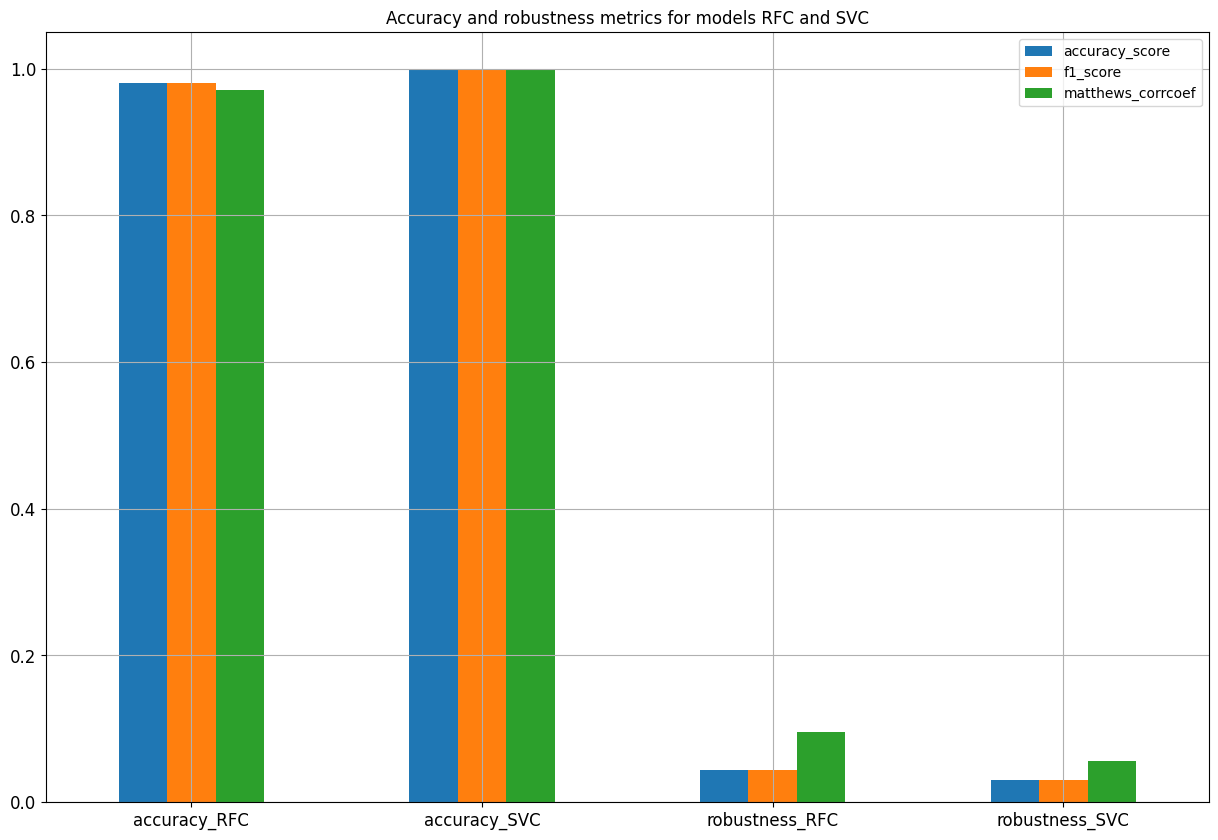

In [17]:
ax = metrics.plot.bar(
    rot=0,
    title='Accuracy and robustness metrics for models RFC and SVC',
    figsize=(15,10),
    fontsize=12,
    logy=False,
    grid=True
)

lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

#ax.hlines(y=1.0, xmin=lims[0], xmax=lims[1])